 # mmWave Radar Contactless Fall Detection: Comparative Representation Benchmark & Model-Size Ablation



 This notebook is the code behind the paper *"Comparative Evaluation of mmWave Radar Data Representations for Contactless Fall Detection in Ambient Assisted Living"*. Every method statement in the paper corresponds to one cell below. All results (tables, figures, JSON) are produced by one top-to-bottom run.



 ## What the notebook does

 * **Data:** TI IWR6843 point clouds, 3 subjects, 102 recordings (51 Fall, 51 ADL), 10 Hz.

 * **Windows:** 10 frames (1.0 s), stride 5, at least 5 points, 320 windows (160 Fall, 160 ADL), extracted once and cached.

 * **Preprocessing:** point filter, per-frame median centering of x and y (z stays absolute), uniform random sampling to N = 32 points per frame (zeros for empty frames).

 * **Representations:**

   * **Rep 1** Doppler-Time Velocity Grid: 32x32 histogram of velocity vs. frame index, 3 identical channels.

   * **Rep 2** 2D Orthogonal Projections: three 32x32 density maps of the whole window (XZ, XY, ZV).

   * **Rep 3** Native 3D Point Set: tensor [5, 320] with [dx, dy, z, v, dz].

 * **Networks:** ResNet-18 (3x3 stride-1 stem, no max-pool) for Rep 1 and Rep 2; a PointNet-style network (shared per-point MLPs + max/average pooling, **no** farthest point sampling, ball query or hierarchy) for Rep 3.

 * **Validation:** 3-fold Leave-One-Subject-Out, seeds 42/52/62. For each seed the predictions of the three folds are pooled, metrics are computed on the 320 pooled windows, and the reported value is the mean +- population std over the three seeds.

 * **Training (all models):** 20 epochs, batch size 32, AdamW (lr 1e-3, weight decay 1e-4 unless stated otherwise), CosineAnnealingLR to 1e-5, cross-entropy, gradient-norm clipping at 1.0. The model after the last epoch is evaluated; there is no validation split and no early stopping. Threshold 0.5 for all metrics except ROC-AUC.



 ## Reproducibility

 * `seed_everything(seed)` seeds Python, NumPy and PyTorch. Each fold uses `fold_seed = seed + 10 * fold_idx`.

 * The model weights are created **after** `seed_everything(fold_seed)`, and the training `DataLoader` uses its own generator seeded with `fold_seed`. A model's result therefore does not depend on which models were trained before it.

 * The point sampling uses a fixed generator (seed 42) while the windows are cached, so all three representations and all seeds see exactly the same 320 windows. Only weight initialization and batch order change between seeds.



 ## Model-size ablation (Section 4)

 * **Rep 1 and Rep 2:** baseline ResNet-18 (11.17M parameters), the same ResNet-18 at half width (about 2.8M), a Narrow CNN (about 104K) and an Ultra-Light CNN (about 26K). The Narrow and Ultra-Light CNNs have **no shortcut connections** and are therefore called CNNs.

 * **Rep 3:** baseline PointNet-style network (about 0.49M), the same per-frame encoder with an LSTM head or a temporal-attention head, and a narrow PointNet-style network.

 * The variants are trained on the same LOSO folds as the baseline and are evaluated **directly on the held-out folds without tuning**, so the best variant is optimistically biased.



 ## Units of the grid representations

 Rep 1 and Rep 2 are binned in **physical units** (z in metres, v in m/s, dx and dy in metres, centred per frame). The standardization (`FoldScaler`) is applied only to the point-set input of Rep 3. Setting `GRID_UNITS = "standardized"` in Cell 1 bins the grids on the standardized z and v instead (+-3 standard deviations); this is only for comparison and is not what the paper reports.

In [1]:
# Cell 1: Environment Setup, Configuration, Global Typography & Deterministic Seeds
import os
import sys
import time
import math
import json
import random
import platform
import textwrap
from pathlib import Path
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

# ---------------- Configuration (these values are the ones used in the paper) ----------------
SEEDS = [42, 52, 62]
EPOCHS = 20
LR = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 32
GRID_UNITS = "physical"      # "physical" (metres, m/s) or "standardized" (old behaviour)
SMOKE_TEST = os.environ.get("FALL_SMOKE_TEST", "0") == "1"   # 1 epoch, only for a quick code check
if SMOKE_TEST:
    EPOCHS = 1
    print("*** SMOKE TEST MODE: 1 epoch, results are NOT valid ***")
assert GRID_UNITS in ("physical", "standardized")

# Global Publication-Quality Typography
plt.rcParams.update({
    "font.size": 14, "axes.labelsize": 15, "axes.titlesize": 16,
    "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,
    "figure.titlesize": 17, "lines.linewidth": 2.0,
    "axes.grid": True, "grid.alpha": 0.4, "grid.linestyle": "--"
})

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def get_cpu_name() -> str:
    """Best-effort CPU model name (printed so that the paper can state the hardware)."""
    try:
        import cpuinfo  # optional: pip install py-cpuinfo
        return cpuinfo.get_cpu_info().get("brand_raw", "unknown")
    except Exception:
        pass
    try:
        if sys.platform.startswith("linux"):
            with open("/proc/cpuinfo") as fh:
                for line in fh:
                    if line.lower().startswith("model name"):
                        return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or "unknown"

CPU_NAME = get_cpu_name()
print(f"PyTorch {torch.__version__} | training device: {DEVICE} | CPU: {CPU_NAME} | "
      f"logical cores: {os.cpu_count()} | torch threads: {torch.get_num_threads()}")
print(f"Seeds {SEEDS} | epochs {EPOCHS} | lr {LR} | weight decay {WEIGHT_DECAY} | batch {BATCH_SIZE} | grid units: {GRID_UNITS}")

# Discover Project Root & Dataset Path
current_path = Path.cwd()
possible_roots = [current_path, current_path.parent, current_path.parent.parent]
PROJECT_ROOT = None
for p in possible_roots:
    if (p / "datasets" / "mmwave-radar-fall-detection" / "GatheredData").exists():
        PROJECT_ROOT = p
        break
    elif (p / "ti_radar_pipeline").exists():
        PROJECT_ROOT = p
if PROJECT_ROOT is None:
    PROJECT_ROOT = current_path

DATA_DIR = PROJECT_ROOT / "datasets" / "mmwave-radar-fall-detection" / "GatheredData"
if not DATA_DIR.exists():
    DATA_DIR = PROJECT_ROOT / "mmWaves" / "datasets" / "mmwave-radar-fall-detection" / "GatheredData"
if os.environ.get("FALL_DATA_DIR"):
    DATA_DIR = Path(os.environ["FALL_DATA_DIR"])

OUTPUT_DIR = PROJECT_ROOT / "ti_radar_pipeline"
BENCHMARKS_DIR = OUTPUT_DIR / "models" / "benchmarks"
if os.environ.get("FALL_OUTPUT_DIR"):
    BENCHMARKS_DIR = Path(os.environ["FALL_OUTPUT_DIR"])
BENCHMARKS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root       : {PROJECT_ROOT}")
print(f"Dataset Directory  : {DATA_DIR}")
print(f"Benchmarks Output  : {BENCHMARKS_DIR}")


PyTorch 2.14.0+cpu | training device: cpu | CPU: AMD Ryzen 7 5700U with Radeon Graphics | logical cores: 16 | torch threads: 8
Seeds [42, 52, 62] | epochs 20 | lr 0.001 | weight decay 0.0001 | batch 32 | grid units: physical
Project Root       : c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves
Dataset Directory  : c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\datasets\mmwave-radar-fall-detection\GatheredData
Benchmarks Output  : c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks


 ---

 ## 1. Input Data Pipeline & File-Level Independence



 Each recording is one CSV file:

 * **Subjects (3):** `Areeb`, `Raffay`, `Towsif` (34 files each = 102 CSVs).

 * **Classes (2):** `Fall` (51 files in `Fall/`) and `ADL` (51 files in `Not/`). The label comes from the immediate parent directory.

 * **Window:** 10 frames (1.0 s at 10 Hz), stride 5 (50% overlap), at least 5 points in the window.

 * **Caching:** windows are extracted once and kept in memory, so every representation and every seed uses the identical 320 windows.

 * **Preprocessing inside the cached windows:** per-frame median centering of x and y, z absolute, uniform random sampling to N = 32 points per frame (with replacement when a frame has fewer than 32 points, zeros for an empty frame). This is **not** the variance-preserving resampling of Jin et al.

In [2]:
# Cell 2: File Ingestion, Temporal Window Extraction & Subject-Level Caching

SUBJECTS = ["Areeb", "Raffay", "Towsif"]
WINDOW_SIZE = 10
STRIDE = 5
MIN_POINTS = 5
N_POINTS = 32

def load_clean_recording(file_path: Path) -> pd.DataFrame:
    df = pd.read_csv(file_path)
    df_clean = df[(df["x"].between(-2.0, 2.0)) &
                  (df["y"].between(0.0, 6.0)) &
                  (df["z"].between(-0.5, 2.2)) &
                  (df["v"].abs() <= 3.0) &
                  (df["snr"] >= 100)].copy()
    if len(df_clean) == 0:
        df_clean = df[(df["x"].between(-3.0, 3.0)) & (df["y"].between(0.0, 8.0))].copy()
    return df_clean

def uniform_sample_frame_points(points: np.ndarray, target_n: int = N_POINTS, rng=None) -> np.ndarray:
    """Uniform random sampling to a fixed size (with replacement if the frame has fewer points)."""
    if rng is None:
        rng = np.random.default_rng(42)
    M = len(points)
    if M == 0:
        return np.zeros((target_n, 4), dtype=np.float32)
    idx = rng.choice(M, size=target_n, replace=(M < target_n))
    return points[idx].astype(np.float32)

def extract_raw_windows_from_df(df: pd.DataFrame, window_size_frames: int = WINDOW_SIZE,
                                stride: int = STRIDE, min_pts_per_win: int = MIN_POINTS) -> List[np.ndarray]:
    if len(df) == 0:
        return []
    frame_dict = {}
    for f_id, df_f in df.groupby("frame"):
        x = df_f["x"].values
        y = df_f["y"].values
        z = df_f["z"].values
        v = df_f["v"].values
        if len(x) > 0:
            dx = x - np.median(x)
            dy = y - np.median(y)
            frame_dict[f_id] = np.column_stack([dx, dy, z, v]).astype(np.float32)
        else:
            frame_dict[f_id] = np.zeros((0, 4), dtype=np.float32)
    if len(frame_dict) == 0:
        return []
    max_frame = int(max(frame_dict.keys()))
    rng = np.random.default_rng(42)
    windows = []
    for start_f in range(0, max_frame - (window_size_frames - 1) + 1, stride):
        end_f = start_f + (window_size_frames - 1)
        win_pts_count = sum(len(frame_dict.get(fi, np.zeros((0, 4)))) for fi in range(start_f, end_f + 1))
        if win_pts_count < min_pts_per_win:
            continue
        win_frames = []
        for fi in range(start_f, end_f + 1):
            pts = frame_dict.get(fi, np.zeros((0, 4), dtype=np.float32))
            win_frames.append(uniform_sample_frame_points(pts, target_n=N_POINTS, rng=rng))
        windows.append(np.array(win_frames, dtype=np.float32))
    return windows

csv_files = sorted(list(DATA_DIR.glob("**/*.csv")))
print(f"Discovered {len(csv_files)} CSV files in: {DATA_DIR}")
assert len(csv_files) == 102, f"Expected 102 CSV files, found {len(csv_files)}"

cached_windows, cached_labels, cached_subjects, cached_subactions = [], [], [], []

t_ingest_start = time.time()
for f in csv_files:
    fname = f.name
    subject = f.stem.split("_")[0]
    is_fall = 1 if f.parent.name.lower() == "fall" else 0   # label from the parent directory only
    sub_action = "fall" if is_fall else ("walk" if "walk" in fname.lower() else ("squat" if "squat" in fname.lower() else ("bow" if "bow" in fname.lower() else "adl")))
    df_clean = load_clean_recording(f)
    wins = extract_raw_windows_from_df(df_clean)
    for w in wins:
        cached_windows.append(w)
        cached_labels.append(is_fall)
        cached_subjects.append(subject)
        cached_subactions.append(sub_action)

all_windows = np.array(cached_windows, dtype=np.float32)     # (320, 10, 32, 4): [dx, dy, z, v]
all_labels = np.array(cached_labels, dtype=np.int64)
all_subjects = np.array(cached_subjects)
all_subactions = np.array(cached_subactions)

print(f"Extracted & Cached {len(all_windows)} total windows in {time.time()-t_ingest_start:.2f}s")
print(f"Class Distribution : Falls = {np.sum(all_labels == 1)} | ADLs = {np.sum(all_labels == 0)}")
for s in SUBJECTS:
    s_mask = (all_subjects == s)
    print(f"  Subject {s:<7}: {np.sum(s_mask):3d} windows (Falls: {np.sum((all_labels == 1) & s_mask)}, ADLs: {np.sum((all_labels == 0) & s_mask)})")
print("Windows per sub-action:", {str(a): int(np.sum(all_subactions == a)) for a in sorted(set(all_subactions))})
if len(all_windows) != 320 or int(np.sum(all_labels == 1)) != 160:
    print(f"WARNING: expected 320 windows (160 Fall, 160 ADL) as in the paper, got {len(all_windows)}")


Discovered 102 CSV files in: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\datasets\mmwave-radar-fall-detection\GatheredData
Extracted & Cached 320 total windows in 2.02s
Class Distribution : Falls = 160 | ADLs = 160
  Subject Areeb  : 112 windows (Falls: 56, ADLs: 56)
  Subject Raffay : 103 windows (Falls: 52, ADLs: 51)
  Subject Towsif : 105 windows (Falls: 52, ADLs: 53)
Windows per sub-action: {'bow': 45, 'fall': 160, 'squat': 50, 'walk': 65}


 ---

 ## 2. Feature Transformations & Representations



 * **FoldScaler:** mean and standard deviation of z and v are computed on the training fold only. It is used for the point-set input of Rep 3 (and for the grids only if `GRID_UNITS = "standardized"`).

 * **Rep 1:** 32x32 histogram of velocity (-3 to 3 m/s) against frame index, divided by the largest count, copied into 3 channels.

 * **Rep 2:** three 32x32 density maps of the whole window, each divided by its own largest count: **XZ** (dx in [-1.5, 1.5] m, z in [-0.5, 2.2] m), **XY** (dx, dy in [-1.5, 1.5] m) and **ZV** (z in [-0.5, 2.2] m, v in [-3, 3] m/s). Points outside the ranges are ignored.

 * **Rep 3:** tensor [5, 320] with [dx, dy, z, v, dz] (z and v standardized), where dz is the height of a point minus the mean height of its frame. The 320 points are ordered frame by frame (10 frames x 32 points).

In [3]:
# Cell 3: Feature Scaler & Representation Transformation Pipeline

class FoldScaler:
    """Leakage-free scaler for z and v, computed strictly on the training fold."""
    def __init__(self):
        self.mean_z = 0.0; self.std_z = 1.0
        self.mean_v = 0.0; self.std_v = 1.0

    def fit(self, X_train_raw: np.ndarray):
        zs = X_train_raw[:, :, :, 2].ravel()
        vs = X_train_raw[:, :, :, 3].ravel()
        self.mean_z = float(np.mean(zs)); self.std_z = float(np.std(zs)) + 1e-6
        self.mean_v = float(np.mean(vs)); self.std_v = float(np.std(vs)) + 1e-6

    def transform(self, X_raw: np.ndarray) -> np.ndarray:
        X_out = X_raw.copy()
        X_out[:, :, :, 2] = (X_out[:, :, :, 2] - self.mean_z) / self.std_z
        X_out[:, :, :, 3] = (X_out[:, :, :, 3] - self.mean_v) / self.std_v
        return X_out

GRID_SIZE = 32
V_RANGE = (-3.0, 3.0)        # m/s   (= the |v| <= 3 filter)
Z_RANGE = (-0.5, 2.2)        # m     (= the z filter)
XY_RANGE = (-1.5, 1.5)       # m     (centred per frame)
if GRID_UNITS == "standardized":
    V_RANGE = (-3.0, 3.0); Z_RANGE = (-3.0, 3.0)   # +-3 standard deviations (comparison only)

def transform_rep1(X_windows: np.ndarray, grid_size: int = GRID_SIZE) -> np.ndarray:
    """Rep 1: Doppler-Time Velocity Grid [N, 3, 32, 32]"""
    X_windows = np.asarray(X_windows)
    N, T, P, C = X_windows.shape
    v_bins = np.linspace(V_RANGE[0], V_RANGE[1], grid_size + 1)
    t_bins = np.linspace(0, T, grid_size + 1)
    t_vals = np.repeat(np.arange(T) + 0.5, P)
    out = []
    for i in range(N):
        v_vals = X_windows[i, :, :, 3].ravel()
        img, _, _ = np.histogram2d(v_vals, t_vals, bins=[v_bins, t_bins])
        if img.max() > 0:
            img = img / img.max()
        out.append(np.stack([img, img, img], axis=0))
    return np.array(out, dtype=np.float32)

def transform_rep2(X_windows: np.ndarray, grid_size: int = GRID_SIZE) -> np.ndarray:
    """Rep 2: 2D Orthogonal Projections [N, 3, 32, 32] = (XZ, XY, ZV)"""
    X_windows = np.asarray(X_windows)
    N, T, P, C = X_windows.shape
    x_bins = np.linspace(XY_RANGE[0], XY_RANGE[1], grid_size + 1)
    y_bins = np.linspace(XY_RANGE[0], XY_RANGE[1], grid_size + 1)
    z_bins = np.linspace(Z_RANGE[0], Z_RANGE[1], grid_size + 1)
    v_bins = np.linspace(V_RANGE[0], V_RANGE[1], grid_size + 1)
    out = []
    for i in range(N):
        win = X_windows[i].reshape(-1, 4)
        dx, dy, z, v = win[:, 0], win[:, 1], win[:, 2], win[:, 3]
        ch0, _, _ = np.histogram2d(dx, z, bins=[x_bins, z_bins])   # XZ
        ch1, _, _ = np.histogram2d(dx, dy, bins=[x_bins, y_bins])  # XY
        ch2, _, _ = np.histogram2d(z, v, bins=[z_bins, v_bins])    # ZV
        for ch in (ch0, ch1, ch2):
            m = ch.max()
            if m > 0:
                ch /= m
        out.append(np.stack([ch0, ch1, ch2], axis=0))
    return np.array(out, dtype=np.float32)

def transform_rep3(X_windows: np.ndarray) -> np.ndarray:
    """Rep 3: Native 3D Point Set [N, 5, 320] = [dx, dy, z, v, dz], points ordered frame by frame."""
    X_windows = np.asarray(X_windows)
    N, T, P, C = X_windows.shape
    out = []
    for i in range(N):
        win = X_windows[i]
        feats = []
        for t_idx in range(T):
            frame_pts = win[t_idx]
            cz = frame_pts[:, 2].mean() if len(frame_pts) > 0 else 0.0
            dz = frame_pts[:, 2] - cz
            feats.append(np.column_stack([frame_pts, dz]))
        out.append(np.concatenate(feats, axis=0).T)
    return np.array(out, dtype=np.float32)

def build_representation(X_raw: np.ndarray, X_scaled: np.ndarray, rep_key: str) -> np.ndarray:
    """Rep 3 always uses the standardized windows; the grids use physical units unless GRID_UNITS == 'standardized'."""
    if rep_key == "rep3":
        return transform_rep3(X_scaled)
    X_grid = X_raw if GRID_UNITS == "physical" else X_scaled
    return transform_rep1(X_grid) if rep_key == "rep1" else transform_rep2(X_grid)

# Per-fold cache of the transformed arrays (identical for all seeds and all model variants)
_FOLD_CACHE: Dict[Tuple[str, int], Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]] = {}
def get_fold_data(rep_key: str, fold_idx: int):
    key = (rep_key, fold_idx)
    if key not in _FOLD_CACHE:
        test_subj = SUBJECTS[fold_idx]
        tr, te = (all_subjects != test_subj), (all_subjects == test_subj)
        scaler = FoldScaler(); scaler.fit(all_windows[tr])
        X_tr = build_representation(all_windows[tr], scaler.transform(all_windows[tr]), rep_key)
        X_te = build_representation(all_windows[te], scaler.transform(all_windows[te]), rep_key)
        _FOLD_CACHE[key] = (X_tr, all_labels[tr], X_te, all_labels[te])
    return _FOLD_CACHE[key]

# Sanity checks of the representations (fail early if something is off)
_probe = get_fold_data("rep2", 0)[0]
print("Rep 2 shape:", _probe.shape, "| non-empty pixels per channel (mean):",
      [round(float((_probe[:, c] > 0).sum(axis=(1, 2)).mean()), 1) for c in range(3)])
assert get_fold_data("rep1", 0)[0].shape[1:] == (3, 32, 32)
assert get_fold_data("rep3", 0)[0].shape[1:] == (5, 320)


Rep 2 shape: (208, 3, 32, 32) | non-empty pixels per channel (mean): [40.7, 50.5, 19.6]


 ---

 ## 3. Model Architectures & Computational Balance Audit



 * **`ResNet18Adaptor(base)`** (Rep 1 and Rep 2): ResNet-18 with a 3x3 stride-1 first layer, no max-pooling, stages of width `base, 2*base, 4*base, 8*base` with two residual blocks each, global average pooling, dropout 0.3 and a linear layer. `base = 64` is the baseline (11,169,858 parameters); `base = 32` is the half-width ablation model (about 2.8M).

 * **`NarrowCNN` / `UltraLightCNN`** (Rep 1 and Rep 2 ablation): small CNNs with a ResNet-style channel layout but **no shortcut connections** (GELU, dropout 0.5).

 * **`PointNetStyleFallDetector`** (Rep 3 baseline): shared per-point MLPs (5-64-64-128, then 128-128-256-512, batch norm + ReLU), global max- and average-pooling over all 320 points, and fully connected layers (1024-256-128-2, dropout 0.3). It has **no farthest point sampling, no ball query and no hierarchy**, so it is a PointNet-style network, not PointNet++.

 * **Rep 3 ablation:** `PointNetLSTMHead` and `PointNetAttentionHead` use the same shared per-point MLPs on every frame separately (32 points per frame, max-pooled to one 512-value vector per frame) and then an LSTM or a temporal-attention layer over the 10 frames. The narrow variant is the baseline network at half width with dropout 0.5.

In [4]:
# Cell 4: Model Architectures

class BasicBlock(nn.Module):
    expansion = 1
    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        return F.relu(out)

class ResNet18Adaptor(nn.Module):
    """ResNet-18 for 32x32 grids. base=64 -> 11,169,858 parameters (baseline); base=32 -> about 2.8M."""
    def __init__(self, in_channels: int = 3, num_classes: int = 2, base: int = 64):
        super().__init__()
        self.in_planes = base
        self.conv1 = nn.Conv2d(in_channels, base, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(base)
        self.layer1 = self._make_layer(BasicBlock, base, 2, stride=1)
        self.layer2 = self._make_layer(BasicBlock, base * 2, 2, stride=2)
        self.layer3 = self._make_layer(BasicBlock, base * 4, 2, stride=2)
        self.layer4 = self._make_layer(BasicBlock, base * 8, 2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(base * 8, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        layers = []
        for s in [stride] + [1] * (num_blocks - 1):
            layers.append(block(self.in_planes, planes, s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer4(self.layer3(self.layer2(self.layer1(out))))
        out = torch.flatten(self.avgpool(out), 1)
        return self.fc(self.dropout(out))

class _SmallCNN(nn.Module):
    """Small CNN with a ResNet-style channel layout and NO shortcut connections."""
    def __init__(self, c: int, hidden: int, in_channels: int = 3, num_classes: int = 2):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_channels, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.GELU())
        self.layer1 = nn.Sequential(nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.GELU())
        self.layer2 = nn.Sequential(nn.Conv2d(c, 2 * c, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(2 * c), nn.GELU())
        self.layer3 = nn.Sequential(nn.Conv2d(2 * c, 4 * c, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(4 * c), nn.GELU())
        self.layer4 = nn.Sequential(nn.Conv2d(4 * c, 8 * c, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(8 * c), nn.GELU())
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Sequential(nn.Dropout(p=0.5), nn.Linear(8 * c, hidden), nn.GELU(), nn.Linear(hidden, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.stem(x)
        out = self.layer4(self.layer3(self.layer2(self.layer1(out))))
        return self.fc(self.avgpool(out).flatten(1))

class NarrowCNN(_SmallCNN):
    """Base channels 16, about 104K parameters."""
    def __init__(self, in_channels: int = 3, num_classes: int = 2):
        super().__init__(c=16, hidden=32, in_channels=in_channels, num_classes=num_classes)

class UltraLightCNN(_SmallCNN):
    """Base channels 8, about 26K parameters."""
    def __init__(self, in_channels: int = 3, num_classes: int = 2):
        super().__init__(c=8, hidden=16, in_channels=in_channels, num_classes=num_classes)

# ---------------- Rep 3 networks ----------------
N_FRAMES = WINDOW_SIZE   # 10 frames per window

class SharedMLP(nn.Module):
    """The same small MLP (1x1 convolutions + batch norm + ReLU) applied to every point."""
    def __init__(self, in_channel: int, mlp: List[int]):
        super().__init__()
        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()
        last = in_channel
        for out_channel in mlp:
            self.convs.append(nn.Conv1d(last, out_channel, 1))
            self.bns.append(nn.BatchNorm1d(out_channel))
            last = out_channel

    def forward(self, points: torch.Tensor) -> torch.Tensor:
        for conv, bn in zip(self.convs, self.bns):
            points = F.relu(bn(conv(points)))
        return points

class PointNetStyleFallDetector(nn.Module):
    """Rep 3 baseline (width=1.0, dropout 0.3): 492,354 parameters. No FPS, no ball query, no hierarchy."""
    def __init__(self, in_features: int = 5, num_classes: int = 2, width: float = 1.0, dropout: float = 0.3):
        super().__init__()
        c = lambda n: max(8, int(round(n * width)))
        self.mlp1 = SharedMLP(in_features, [c(64), c(64), c(128)])
        self.mlp2 = SharedMLP(c(128), [c(128), c(256), c(512)])
        self.fc1 = nn.Linear(2 * c(512), c(256))
        self.bn1 = nn.BatchNorm1d(c(256))
        self.drop1 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(c(256), c(128))
        self.fc3 = nn.Linear(c(128), num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:          # x: [B, 5, 320]
        feat = self.mlp2(self.mlp1(x))
        global_feat = torch.cat([torch.max(feat, 2)[0], torch.mean(feat, 2)], dim=1)
        out = self.drop1(F.relu(self.bn1(self.fc1(global_feat))))
        return self.fc3(F.relu(self.fc2(out)))

def split_frames(x: torch.Tensor) -> torch.Tensor:
    """[B, 5, 320] (10 frames x 32 points, frame by frame) -> [B*10, 5, 32]. (A plain view(B*10, 5, 32) would mix channels and points.)"""
    B = x.size(0)
    return x.reshape(B, 5, N_FRAMES, N_POINTS).permute(0, 2, 1, 3).reshape(B * N_FRAMES, 5, N_POINTS)

class FrameEncoder(nn.Module):
    """Same shared MLPs as the baseline, applied to every frame separately and max-pooled: [B, 5, 320] -> [B, 10, 512]."""
    def __init__(self, in_features: int = 5):
        super().__init__()
        self.mlp1 = SharedMLP(in_features, [64, 64, 128])
        self.mlp2 = SharedMLP(128, [128, 256, 512])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B = x.size(0)
        f = self.mlp2(self.mlp1(split_frames(x)))        # [B*10, 512, 32]
        return torch.max(f, dim=2)[0].reshape(B, N_FRAMES, 512)

class PointNetLSTMHead(nn.Module):
    def __init__(self, in_features: int = 5, num_classes: int = 2):
        super().__init__()
        self.encoder = FrameEncoder(in_features)
        self.lstm = nn.LSTM(input_size=512, hidden_size=128, batch_first=True)
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        _, (h_n, _) = self.lstm(self.encoder(x))
        return self.fc(h_n[-1])

class PointNetAttentionHead(nn.Module):
    def __init__(self, in_features: int = 5, num_classes: int = 2):
        super().__init__()
        self.encoder = FrameEncoder(in_features)
        self.attn = nn.Sequential(nn.Linear(512, 128), nn.Tanh(), nn.Linear(128, 1))
        self.fc = nn.Sequential(nn.Dropout(0.4), nn.Linear(512, 64), nn.ReLU(), nn.Linear(64, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        seq = self.encoder(x)                             # [B, 10, 512]
        w = F.softmax(self.attn(seq), dim=1)
        return self.fc(torch.sum(seq * w, dim=1))

# ---------------- Model registry (the paper's Table V) ----------------
def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def fmt_params(n: int) -> str:
    return f"{n/1e6:.2f}M" if n >= 400_000 else f"{round(n/1e3)}K"

def make_specs(rep_key: str) -> List[Dict[str, Any]]:
    """Index 0 is always the baseline of the representation. 'wd' is the AdamW weight decay."""
    if rep_key in ("rep1", "rep2"):
        specs = [
            {"name": "Baseline ResNet-18",       "build": lambda: ResNet18Adaptor(base=64), "wd": WEIGHT_DECAY},
            {"name": "ResNet-18 half width",     "build": lambda: ResNet18Adaptor(base=32), "wd": WEIGHT_DECAY},
            {"name": "Narrow CNN, p=0.5",       "build": lambda: NarrowCNN(),              "wd": 1e-2},
            {"name": "Ultra-Light CNN, p=0.5",  "build": lambda: UltraLightCNN(),          "wd": 1e-2},
        ]
    else:
        specs = [
            {"name": "Baseline PointNet-style",        "build": lambda: PointNetStyleFallDetector(),                        "wd": WEIGHT_DECAY},
            {"name": "LSTM head",                      "build": lambda: PointNetLSTMHead(),                                 "wd": 1e-3},
            {"name": "Attention head",                 "build": lambda: PointNetAttentionHead(),                            "wd": 1e-3},
            {"name": "Narrow PointNet-style, p=0.5",  "build": lambda: PointNetStyleFallDetector(width=0.5, dropout=0.5),  "wd": 1e-2},
        ]
    for s in specs:
        s["params"] = count_params(s["build"]())
        s["label"] = f"{s['name']} ({fmt_params(s['params'])})"
    return specs

REPRESENTATIONS = ["rep1", "rep2", "rep3"]
MODEL_SPECS = {rk: make_specs(rk) for rk in REPRESENTATIONS}


In [5]:
# Cell 5: Unit test of the frame split, forward-pass shape check & Computational Balance Audit

def test_frame_split():
    B = 3
    x = torch.zeros(B, 5, N_FRAMES * N_POINTS)
    for t in range(N_FRAMES):
        x[:, 0, t * N_POINTS:(t + 1) * N_POINTS] = float(t)                # channel 0 = frame index
    x[:, 1, :] = torch.arange(N_FRAMES * N_POINTS, dtype=torch.float32) % N_POINTS   # channel 1 = point index
    out = split_frames(x)
    assert out.shape == (B * N_FRAMES, 5, N_POINTS)
    for b in range(B):
        for t in range(N_FRAMES):
            row = out[b * N_FRAMES + t]
            assert torch.all(row[0] == float(t)), "frame split mixes frames"
            assert torch.equal(row[1], torch.arange(N_POINTS, dtype=torch.float32)), "frame split mixes points"
    # the split must agree with the real Rep 3 layout produced by transform_rep3
    win = np.zeros((1, N_FRAMES, N_POINTS, 4), dtype=np.float32)
    for t in range(N_FRAMES):
        win[0, t, :, 0] = t                      # dx = frame index
        win[0, t, :, 1] = np.arange(N_POINTS)    # dy = point index
    r3 = torch.from_numpy(transform_rep3(win))
    sp = split_frames(r3)
    assert all(torch.all(sp[t, 0] == float(t)) for t in range(N_FRAMES)), "transform_rep3 layout != split_frames layout"
    print("Frame-split unit test passed.")

test_frame_split()

def audit_models():
    rows = []
    for rk in REPRESENTATIONS:
        shape = (32, 3, 32, 32) if rk in ("rep1", "rep2") else (32, 5, N_FRAMES * N_POINTS)
        dummy = torch.randn(*shape)
        for spec in MODEL_SPECS[rk]:
            m = spec["build"]().eval()
            with torch.no_grad():
                out = m(dummy)
            assert out.shape == (32, 2), f"{spec['name']}: wrong output shape {tuple(out.shape)}"
            t0 = time.time()
            with torch.no_grad():
                for _ in range(5): _ = m(dummy)
            lat = (time.time() - t0) / 5.0 * 1000.0
            rows.append({"Representation": rk, "Model": spec["name"], "Input Shape": str(list(shape)),
                         "Parameters": f"{spec['params']:,}", "CPU Step Latency": f"{lat:.1f} ms/batch"})
    print("=== ARCHITECTURAL & COMPUTATIONAL BALANCE AUDIT ===")
    print(pd.DataFrame(rows).to_markdown(index=False))
    print()

audit_models()


Frame-split unit test passed.
=== ARCHITECTURAL & COMPUTATIONAL BALANCE AUDIT ===
| Representation   | Model                        | Input Shape     |   Parameters | CPU Step Latency   |
|:-----------------|:-----------------------------|:----------------|-------------:|:-------------------|
| rep1             | Baseline ResNet-18           | [32, 3, 32, 32] |   11,169,858 | 224.9 ms/batch     |
| rep1             | ResNet-18 half width         | [32, 3, 32, 32] |    2,795,554 | 67.6 ms/batch      |
| rep1             | Narrow CNN, p=0.5            | [32, 3, 32, 32] |      104,210 | 8.7 ms/batch       |
| rep1             | Ultra-Light CNN, p=0.5       | [32, 3, 32, 32] |       26,314 | 4.7 ms/batch       |
| rep2             | Baseline ResNet-18           | [32, 3, 32, 32] |   11,169,858 | 236.1 ms/batch     |
| rep2             | ResNet-18 half width         | [32, 3, 32, 32] |    2,795,554 | 68.6 ms/batch      |
| rep2             | Narrow CNN, p=0.5            | [32, 3, 32, 32] | 

In [6]:
# Cell 6: Training Engine & Metric Evaluation Utilities

def train_and_eval_fold(build_model, X_tr, y_tr, X_te, y_te, weight_decay: float, fold_seed: int):
    """Trains one model on one LOSO fold and returns the test labels and fall probabilities.
    The weights are created AFTER seeding and the loader has its own generator, so the result of a model does not
    depend on which models were trained before it."""
    seed_everything(fold_seed)
    model = build_model().to(DEVICE)
    train_ds = TensorDataset(torch.from_numpy(X_tr).float(), torch.tensor(y_tr, dtype=torch.long))
    test_ds = TensorDataset(torch.from_numpy(X_te).float(), torch.tensor(y_te, dtype=torch.long))
    gen = torch.Generator()
    gen.manual_seed(fold_seed)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False, generator=gen)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        model.train()
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        scheduler.step()

    model.eval()                      # the model after the last epoch is evaluated
    probs = []
    with torch.no_grad():
        for batch_x, _ in test_loader:
            probs.extend(F.softmax(model(batch_x.to(DEVICE)), dim=1)[:, 1].cpu().numpy().tolist())
    return np.array(y_te), np.array(probs)

def compute_classification_metrics(y_true: np.ndarray, y_probs: np.ndarray, threshold: float = 0.5) -> Dict[str, Any]:
    y_pred = (y_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    recall = float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0
    precision = float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0
    accuracy = float((tp + tn) / len(y_true)) if len(y_true) > 0 else 0.0
    f1_macro = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
    try:
        roc_auc = float(roc_auc_score(y_true, y_probs))
    except Exception:
        roc_auc = 0.5
    far = float(fp / (tn + fp)) if (tn + fp) > 0 else 0.0     # FP / (FP + TN) over ALL ADL windows
    return {"macro_f1": f1_macro, "recall": recall, "precision": precision, "accuracy": accuracy,
            "roc_auc": roc_auc, "confounder_far": far,
            "confusion_matrix": {"TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn)}}

def evaluate_variant(rep_key: str, spec: Dict[str, Any], seed: int):
    """3-fold LOSO for one model and one seed. Returns the pooled out-of-fold labels, probabilities and metrics."""
    oof_true, oof_probs = [], []
    for fold_idx in range(len(SUBJECTS)):
        X_tr, y_tr, X_te, y_te = get_fold_data(rep_key, fold_idx)
        y_f, p_f = train_and_eval_fold(spec["build"], X_tr, y_tr, X_te, y_te, spec["wd"], seed + fold_idx * 10)
        oof_true.extend(y_f.tolist()); oof_probs.extend(p_f.tolist())
    oof_true, oof_probs = np.array(oof_true), np.array(oof_probs)
    return oof_true, oof_probs, compute_classification_metrics(oof_true, oof_probs)

def aggregate(metric_dicts: List[Dict[str, Any]]) -> Dict[str, Dict[str, float]]:
    out = {}
    for k in ("macro_f1", "recall", "precision", "accuracy", "roc_auc", "confounder_far"):
        vals = [m[k] for m in metric_dicts]
        out[k] = {"mean": float(np.mean(vals)), "std": float(np.std(vals))}     # population std over seeds
    return out

def measure_latency(rep_key: str, spec: Dict[str, Any], n_rep: int = 200) -> Dict[str, float]:
    """Latency of ONE window on the CPU: building the representation (standardization + transform; filtering, centering
    and sampling are not included) plus one forward pass with batch size 1."""
    raw = all_windows[:1]
    scaler = FoldScaler(); scaler.fit(all_windows)
    for _ in range(10):
        _ = build_representation(raw, scaler.transform(raw), rep_key)
    t0 = time.perf_counter()
    for _ in range(n_rep):
        rep = build_representation(raw, scaler.transform(raw), rep_key)
    prep_ms = (time.perf_counter() - t0) / n_rep * 1000.0

    model = spec["build"]().to("cpu").eval()
    dummy = torch.from_numpy(rep).float()
    with torch.no_grad():
        for _ in range(20): _ = model(dummy)
        t0 = time.perf_counter()
        for _ in range(n_rep): _ = model(dummy)
        fwd_ms = (time.perf_counter() - t0) / n_rep * 1000.0
    return {"prep": round(prep_ms, 3), "forward": round(fwd_ms, 3), "total": round(prep_ms + fwd_ms, 3)}


In [7]:
# Cell 7: Multi-Seed LOSO Cross-Validation Benchmark (baseline model of each representation)

rep_display_names = {"rep1": "Rep_1_Doppler_Time", "rep2": "Rep_2_Orthogonal_Projections", "rep3": "Rep_3_Native_3D_Point_Sets"}

benchmark_results = {
    "experiment_metadata": {
        "seeds": SEEDS, "epochs": EPOCHS, "learning_rate": LR, "batch_size": BATCH_SIZE,
        "window_size": WINDOW_SIZE, "stride": STRIDE, "resampling_N": N_POINTS, "folds": SUBJECTS,
        "grid_units": GRID_UNITS, "grid_ranges": {"v": list(V_RANGE), "z": list(Z_RANGE), "xy": list(XY_RANGE)},
        "cpu": CPU_NAME, "torch_threads": torch.get_num_threads(), "torch_version": torch.__version__,
        "smoke_test": SMOKE_TEST
    },
    "representations": {},
    "seed_ablation_comparison": {f"seed_{s}": {} for s in SEEDS}
}
all_runs_oof = {rk: {} for rk in REPRESENTATIONS}

for rep_key in REPRESENTATIONS:
    name = rep_display_names[rep_key]
    base_spec = MODEL_SPECS[rep_key][0]
    print("\n" + "=" * 70)
    print(f"BENCHMARKING: {name} ({rep_key}) | model: {base_spec['label']}")
    print(f"Runs: {len(SEEDS)} | Epochs: {EPOCHS} | LR: {LR} | Batch Size: {BATCH_SIZE}")
    print("=" * 70)

    run_metrics = []
    for run_idx, seed in enumerate(SEEDS):
        t0 = time.time()
        y_true, y_probs, m = evaluate_variant(rep_key, base_spec, seed)
        run_metrics.append(m)
        all_runs_oof[rep_key][seed] = {"true": y_true, "probs": y_probs}
        benchmark_results["seed_ablation_comparison"][f"seed_{seed}"][name] = m
        print(f"  Run {run_idx+1}/{len(SEEDS)} (Seed {seed}) [{time.time()-t0:.1f}s] -> Acc: {m['accuracy']*100:.2f}%, "
              f"Recall: {m['recall']*100:.2f}%, Macro F1: {m['macro_f1']*100:.2f}%, ROC-AUC: {m['roc_auc']:.4f}, FAR: {m['confounder_far']*100:.2f}%")

    pooled = {k: int(sum(m["confusion_matrix"][k] for m in run_metrics)) for k in ("TP", "FP", "TN", "FN")}
    benchmark_results["representations"][name] = {
        "model": base_spec["name"], "parameters": base_spec["params"],
        **aggregate(run_metrics),
        "confusion_matrix_seed42": run_metrics[0]["confusion_matrix"],          # the one shown in Fig. 2 and Table III
        "confusion_matrix_per_seed": {f"seed_{s}": m["confusion_matrix"] for s, m in zip(SEEDS, run_metrics)},
        "confusion_matrix_pooled_all_seeds": pooled,
        "latency_ms": measure_latency(rep_key, base_spec)
    }



BENCHMARKING: Rep_1_Doppler_Time (rep1) | model: Baseline ResNet-18 (11.17M)
Runs: 3 | Epochs: 20 | LR: 0.001 | Batch Size: 32
  Run 1/3 (Seed 42) [447.5s] -> Acc: 52.19%, Recall: 49.38%, Macro F1: 52.15%, ROC-AUC: 0.5514, FAR: 45.00%
  Run 2/3 (Seed 52) [473.9s] -> Acc: 53.75%, Recall: 45.62%, Macro F1: 53.44%, ROC-AUC: 0.5464, FAR: 38.12%
  Run 3/3 (Seed 62) [453.8s] -> Acc: 53.75%, Recall: 61.88%, Macro F1: 53.44%, ROC-AUC: 0.5571, FAR: 54.37%

BENCHMARKING: Rep_2_Orthogonal_Projections (rep2) | model: Baseline ResNet-18 (11.17M)
Runs: 3 | Epochs: 20 | LR: 0.001 | Batch Size: 32
  Run 1/3 (Seed 42) [474.3s] -> Acc: 72.50%, Recall: 65.62%, Macro F1: 72.37%, ROC-AUC: 0.8007, FAR: 20.62%
  Run 2/3 (Seed 52) [419.7s] -> Acc: 68.75%, Recall: 66.25%, Macro F1: 68.73%, ROC-AUC: 0.7873, FAR: 28.75%
  Run 3/3 (Seed 62) [515.9s] -> Acc: 70.94%, Recall: 61.88%, Macro F1: 70.70%, ROC-AUC: 0.8176, FAR: 20.00%

BENCHMARKING: Rep_3_Native_3D_Point_Sets (rep3) | model: Baseline PointNet-style (0.4

In [8]:
# Cell 8: Structured JSON Export & Comparative Table

json_out_path = BENCHMARKS_DIR / "results_benchmark.json"
with open(json_out_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_results, f, indent=2)
print(f"Successfully exported benchmark JSON to: {json_out_path}")

rows = []
for rk in REPRESENTATIONS:
    info = benchmark_results["representations"][rep_display_names[rk]]
    rows.append({
        "Representation": rep_display_names[rk].replace("_", " "),
        "Model (params)": f"{info['model']} ({fmt_params(info['parameters'])})",
        "Macro F1 (%)": f"{info['macro_f1']['mean']*100:.2f} ± {info['macro_f1']['std']*100:.2f}",
        "Recall (%)": f"{info['recall']['mean']*100:.2f} ± {info['recall']['std']*100:.2f}",
        "Precision (%)": f"{info['precision']['mean']*100:.2f} ± {info['precision']['std']*100:.2f}",
        "Accuracy (%)": f"{info['accuracy']['mean']*100:.2f} ± {info['accuracy']['std']*100:.2f}",
        "ROC-AUC": f"{info['roc_auc']['mean']:.4f} ± {info['roc_auc']['std']:.4f}",
        "FAR (%)": f"{info['confounder_far']['mean']*100:.2f} ± {info['confounder_far']['std']*100:.2f}",
        "Prep (ms)": f"{info['latency_ms']['prep']:.2f}",
        "Forward (ms)": f"{info['latency_ms']['forward']:.2f}",
        "Total (ms)": f"{info['latency_ms']['total']:.2f}",
    })
print("\n" + "=" * 100)
print("        TI mmWave Radar Fall Detection: Benchmark Summary Table")
print(f"        Latency: one window, batch size 1, CPU = {CPU_NAME}, torch threads = {torch.get_num_threads()}")
print("=" * 100)
print(pd.DataFrame(rows).to_markdown(index=False))
print("=" * 100)

print("\nConfusion matrices per seed (TN / FP / FN / TP):")
for rk in REPRESENTATIONS:
    for s, cm in benchmark_results["representations"][rep_display_names[rk]]["confusion_matrix_per_seed"].items():
        print(f"  {rk} {s}: TN={cm['TN']} FP={cm['FP']} FN={cm['FN']} TP={cm['TP']}")


Successfully exported benchmark JSON to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\results_benchmark.json

        TI mmWave Radar Fall Detection: Benchmark Summary Table
        Latency: one window, batch size 1, CPU = AMD Ryzen 7 5700U with Radeon Graphics, torch threads = 8
| Representation               | Model (params)                  | Macro F1 (%)   | Recall (%)   | Precision (%)   | Accuracy (%)   | ROC-AUC         | FAR (%)      |   Prep (ms) |   Forward (ms) |   Total (ms) |
|:-----------------------------|:--------------------------------|:---------------|:-------------|:----------------|:---------------|:----------------|:-------------|------------:|---------------:|-------------:|
| Rep 1 Doppler Time           | Baseline ResNet-18 (11.17M)     | 53.01 ± 0.61   | 52.29 ± 6.95 | 53.34 ± 0.89    | 53.23 ± 0.74   | 0.5516 ± 0.0044 | 45.83 ± 6.66 |        0.35 |          20.54 |        20.89 |
| Rep 2 Orthogonal Projections | Baselin

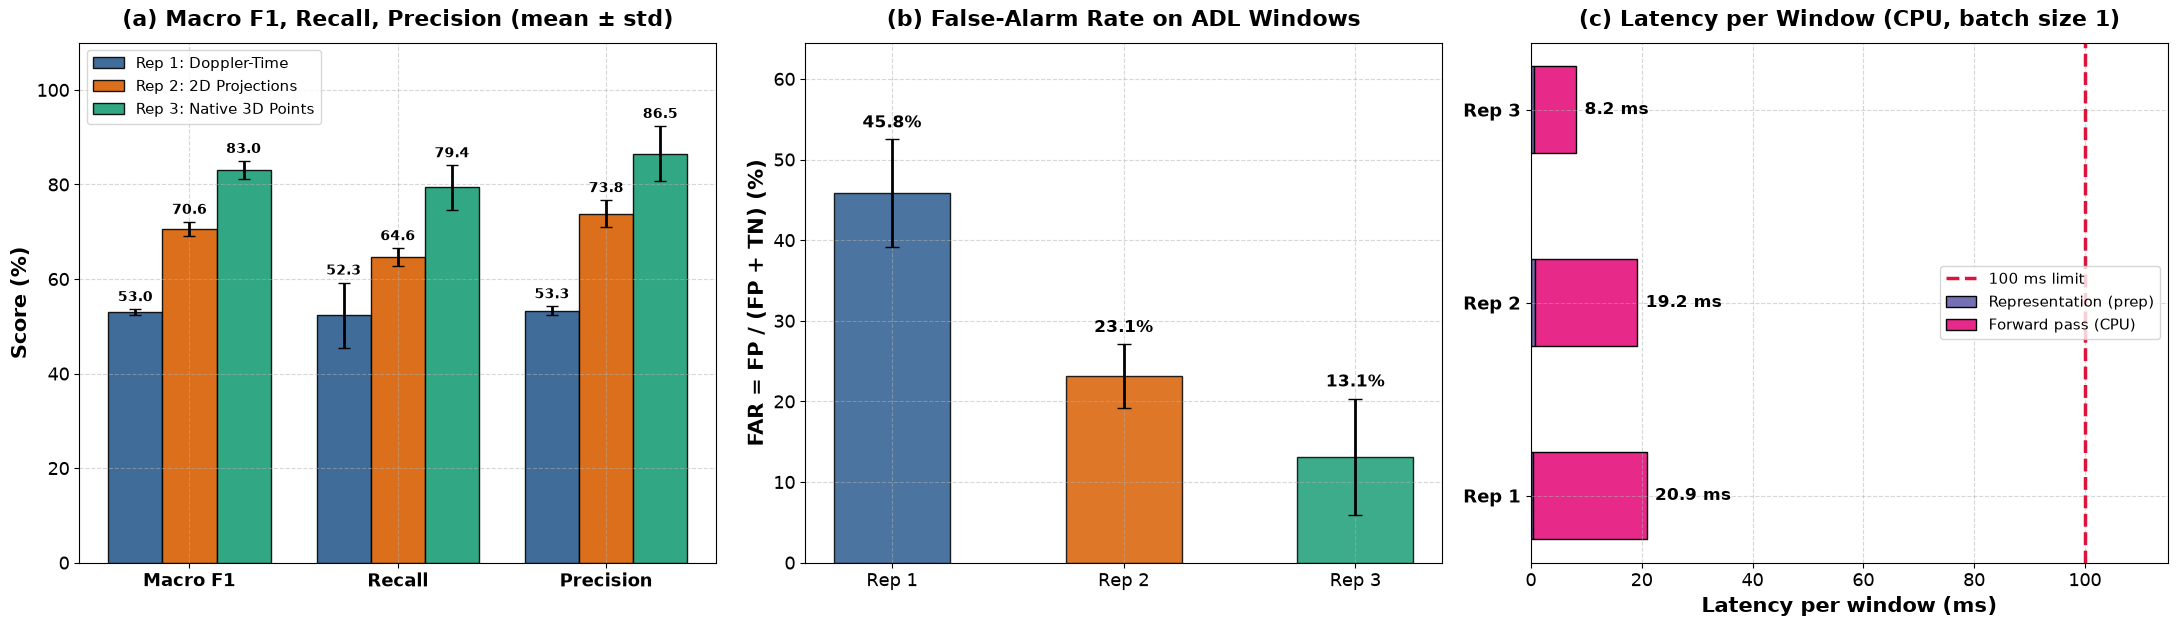

Saved Figure 1 to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\figure1_representation_benchmark.png


In [9]:
# Cell 9: Figure 1 - Benchmark over 3 seeds (mean ± std)
rep_keys = [rep_display_names[rk] for rk in REPRESENTATIONS]
rep_labels = ["Rep 1: Doppler-Time", "Rep 2: 2D Projections", "Rep 3: Native 3D Points"]
rep_short = ["Rep 1", "Rep 2", "Rep 3"]
colors = ["#2b5c8f", "#d95f02", "#1b9e77"]

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

# (a) Macro F1, Recall, Precision
metrics = ["macro_f1", "recall", "precision"]
metric_names = ["Macro F1", "Recall", "Precision"]
x = np.arange(len(metrics))
width = 0.26
for i, (rk, rl, col) in enumerate(zip(rep_keys, rep_labels, colors)):
    means = [benchmark_results["representations"][rk][m]["mean"] * 100 for m in metrics]
    stds = [benchmark_results["representations"][rk][m]["std"] * 100 for m in metrics]
    rects = axes[0].bar(x + (i - 1) * width, means, width, yerr=stds, capsize=4, label=rl, color=col, alpha=0.9, edgecolor="black")
    for rect, mean_val, std_val in zip(rects, means, stds):
        axes[0].annotate(f"{mean_val:.1f}", xy=(rect.get_x() + rect.get_width() / 2, rect.get_height() + std_val + 1.0),
                         ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].set_title("(a) Macro F1, Recall, Precision (mean ± std)", fontweight="bold", pad=12)
axes[0].set_xticks(x); axes[0].set_xticklabels(metric_names, fontweight="bold")
axes[0].set_ylabel("Score (%)", fontweight="bold"); axes[0].set_ylim(0, 110)
axes[0].legend(loc="upper left", frameon=True, fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)

# (b) False-alarm rate on ADL windows
far_means = [benchmark_results["representations"][rk]["confounder_far"]["mean"] * 100 for rk in rep_keys]
far_stds = [benchmark_results["representations"][rk]["confounder_far"]["std"] * 100 for rk in rep_keys]
b_far = axes[1].bar(rep_short, far_means, yerr=far_stds, capsize=5, color=colors, alpha=0.85, edgecolor="black", width=0.5)
for rect, m_val, s_val in zip(b_far, far_means, far_stds):
    axes[1].annotate(f"{m_val:.1f}%", xy=(rect.get_x() + rect.get_width() / 2, rect.get_height() + s_val + 1.0),
                     ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[1].set_title("(b) False-Alarm Rate on ADL Windows", fontweight="bold", pad=12)
axes[1].set_ylabel("FAR = FP / (FP + TN) (%)", fontweight="bold")
axes[1].set_ylim(0, max(m + s for m, s in zip(far_means, far_stds)) + 12)
axes[1].grid(True, linestyle="--", alpha=0.5)

# (c) Latency per window vs. 100 ms limit
prep_times = [benchmark_results["representations"][rk]["latency_ms"]["prep"] for rk in rep_keys]
fwd_times = [benchmark_results["representations"][rk]["latency_ms"]["forward"] for rk in rep_keys]
y_pos = np.arange(len(rep_short))
axes[2].barh(y_pos, prep_times, label="Representation (prep)", color="#7570b3", edgecolor="black", height=0.45)
axes[2].barh(y_pos, fwd_times, left=prep_times, label="Forward pass (CPU)", color="#e7298a", edgecolor="black", height=0.45)
axes[2].axvline(x=100.0, color="crimson", linestyle="--", linewidth=2.5, label="100 ms limit")
for idx, (p_t, f_t) in enumerate(zip(prep_times, fwd_times)):
    axes[2].text(p_t + f_t + 1.5, idx, f"{p_t + f_t:.1f} ms", va="center", fontweight="bold", fontsize=12)
axes[2].set_yticks(y_pos); axes[2].set_yticklabels(rep_short, fontweight="bold")
axes[2].set_xlabel("Latency per window (ms)", fontweight="bold")
axes[2].set_title("(c) Latency per Window (CPU, batch size 1)", fontweight="bold", pad=12)
axes[2].set_xlim(0, 115)
axes[2].legend(loc="center right", frameon=True, fontsize=11)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig1_path = BENCHMARKS_DIR / "figure1_representation_benchmark.png"
plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Figure 1 to: {fig1_path}")


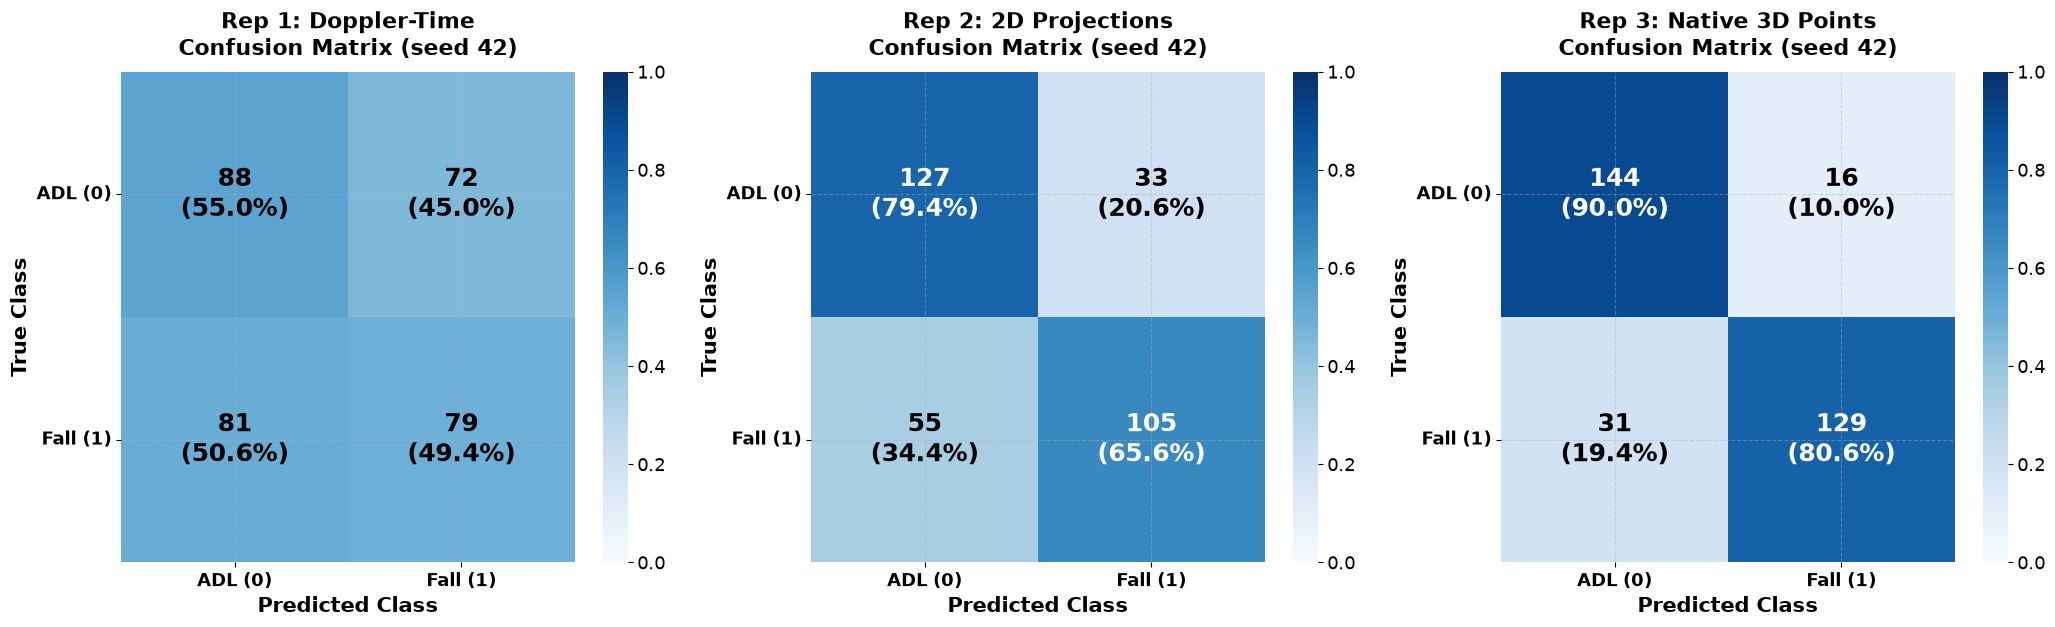

Saved Figure 2 to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\figure2_confusion_matrices.png


In [10]:
# Cell 10: Figure 2 - Confusion matrices of seed 42 (rows normalized)
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for i, (rk, rl) in enumerate(zip(rep_keys, rep_labels)):
    cm_dict = benchmark_results["representations"][rk]["confusion_matrix_seed42"]
    cm_arr = np.array([[cm_dict["TN"], cm_dict["FP"]], [cm_dict["FN"], cm_dict["TP"]]])
    cm_norm = cm_arr.astype(float) / cm_arr.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=False, cmap="Blues", cbar=True, ax=axes[i], vmin=0, vmax=1.0)
    for r in range(2):
        for c in range(2):
            col = "white" if cm_norm[r, c] > 0.55 else "black"
            axes[i].text(c + 0.5, r + 0.5, f"{cm_arr[r, c]}\n({cm_norm[r, c] * 100:.1f}%)",
                         ha="center", va="center", color=col, fontsize=18, fontweight="bold")
    axes[i].set_title(f"{rl}\nConfusion Matrix (seed 42)", fontweight="bold", pad=12)
    axes[i].set_xlabel("Predicted Class", fontweight="bold")
    axes[i].set_ylabel("True Class", fontweight="bold")
    axes[i].set_xticklabels(["ADL (0)", "Fall (1)"], fontweight="bold")
    axes[i].set_yticklabels(["ADL (0)", "Fall (1)"], fontweight="bold", rotation=0)
plt.tight_layout()
fig2_path = BENCHMARKS_DIR / "figure2_confusion_matrices.png"
plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Figure 2 to: {fig2_path}")


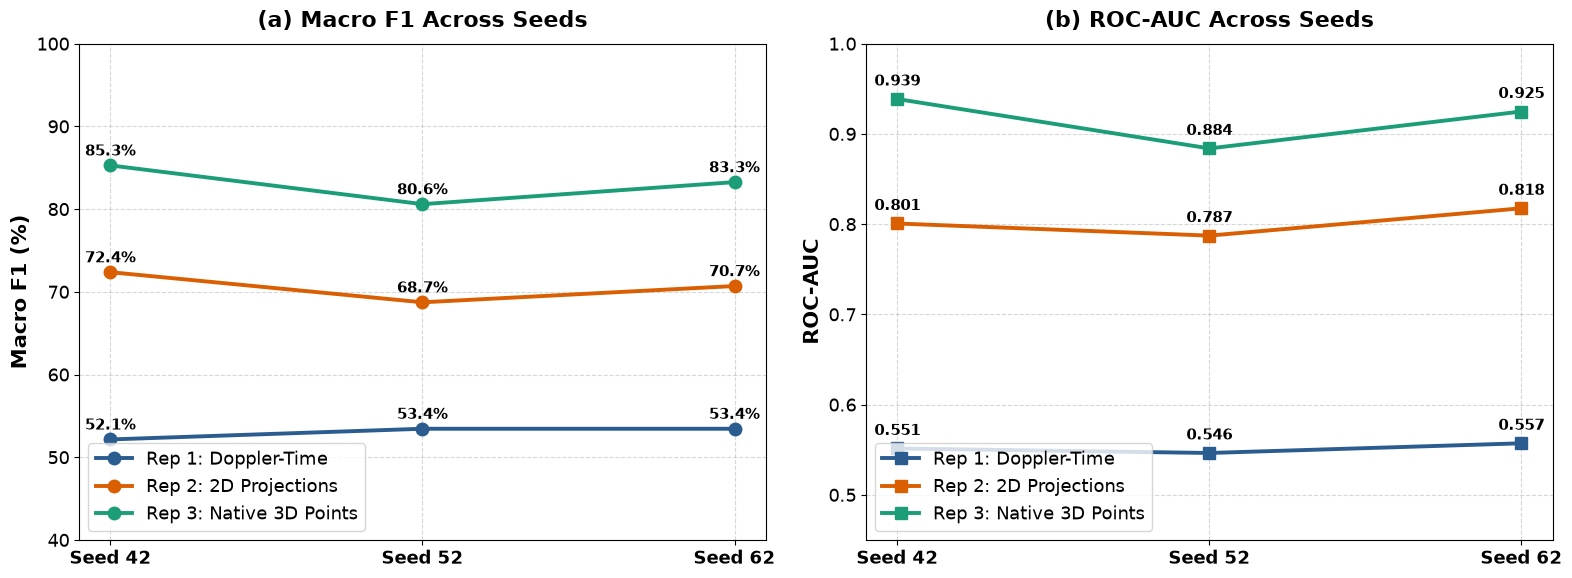

Saved Figure 3 to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\figure3_seed_stability.png


In [11]:
# Cell 11: Figure 3 - Seed stability
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
seeds_str = [f"Seed {s}" for s in SEEDS]
x_seeds = np.arange(len(SEEDS))

for rk, rl, col in zip(rep_keys, rep_labels, colors):
    f1_vals = [benchmark_results["seed_ablation_comparison"][f"seed_{s}"][rk]["macro_f1"] * 100 for s in SEEDS]
    axes[0].plot(x_seeds, f1_vals, marker="o", linewidth=2.8, markersize=9, label=rl, color=col)
    for x_i, y_i in zip(x_seeds, f1_vals):
        axes[0].annotate(f"{y_i:.1f}%", xy=(x_i, y_i + 1.2), ha="center", fontweight="bold", fontsize=11)
axes[0].set_title("(a) Macro F1 Across Seeds", fontweight="bold", pad=12)
axes[0].set_xticks(x_seeds); axes[0].set_xticklabels(seeds_str, fontweight="bold")
axes[0].set_ylabel("Macro F1 (%)", fontweight="bold"); axes[0].set_ylim(40, 100)
axes[0].legend(loc="lower left", frameon=True); axes[0].grid(True, linestyle="--", alpha=0.5)

for rk, rl, col in zip(rep_keys, rep_labels, colors):
    auc_vals = [benchmark_results["seed_ablation_comparison"][f"seed_{s}"][rk]["roc_auc"] for s in SEEDS]
    axes[1].plot(x_seeds, auc_vals, marker="s", linewidth=2.8, markersize=9, label=rl, color=col)
    for x_i, y_i in zip(x_seeds, auc_vals):
        axes[1].annotate(f"{y_i:.3f}", xy=(x_i, y_i + 0.015), ha="center", fontweight="bold", fontsize=11)
axes[1].set_title("(b) ROC-AUC Across Seeds", fontweight="bold", pad=12)
axes[1].set_xticks(x_seeds); axes[1].set_xticklabels(seeds_str, fontweight="bold")
axes[1].set_ylabel("ROC-AUC", fontweight="bold"); axes[1].set_ylim(0.45, 1.0)
axes[1].legend(loc="lower left", frameon=True); axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig3_path = BENCHMARKS_DIR / "figure3_seed_stability.png"
plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Figure 3 to: {fig3_path}")


 ---

 ## 4. Model-Size & Architecture Ablation (all three representations)



 * Each variant is trained with the **same LOSO folds, seeds, epochs and optimizer** as the baseline. Only the model (and, where stated, dropout and weight decay) changes. The baseline results are taken from Cell 7 (same seeds), so the deltas are per seed.

 * **Rep 1 and Rep 2:** Baseline ResNet-18 (11.17M) / ResNet-18 half width (about 2.8M, weight decay 1e-4) / Narrow CNN (about 104K, dropout 0.5, weight decay 1e-2) / Ultra-Light CNN (about 26K, dropout 0.5, weight decay 1e-2).

 * **Rep 3:** Baseline PointNet-style (about 0.49M) / LSTM head (weight decay 1e-3) / Attention head (weight decay 1e-3) / Narrow PointNet-style (half width, dropout 0.5, weight decay 1e-2).

 * **Important:** the variants are evaluated directly on the held-out folds and are not tuned on a separate validation set. The best variant is therefore optimistically biased and differences of one or two points are not reliable.

In [12]:
# Cell 12: Multi-Seed Ablation Runner

arch_results_by_rep = {rk: {f"seed_{s}": {} for s in SEEDS} for rk in REPRESENTATIONS}

print("=" * 90)
print("MODEL-SIZE & ARCHITECTURE ABLATION FOR ALL 3 REPRESENTATIONS")
print("Baselines come from Cell 7 (same seeds, same folds)")
print("=" * 90)

for rep_key in REPRESENTATIONS:
    name = rep_display_names[rep_key]
    specs = MODEL_SPECS[rep_key]
    print("\n" + "#" * 75)
    print(f"### {name} ({rep_key.upper()}) ###")
    print("#" * 75)
    for run_idx, seed in enumerate(SEEDS):
        print(f"\n--- [{rep_key.upper()}] Run {run_idx+1}/{len(SEEDS)} (Seed {seed}) ---")
        y_true_base = all_runs_oof[rep_key][seed]["true"]
        m_base = benchmark_results["seed_ablation_comparison"][f"seed_{seed}"][name]
        arch_results_by_rep[rep_key][f"seed_{seed}"][specs[0]["label"]] = m_base
        print(f"  * {specs[0]['label']:<44}: Macro F1 = {m_base['macro_f1']*100:.2f}%, ROC-AUC = {m_base['roc_auc']:.4f} (baseline, Cell 7)")
        for spec in specs[1:]:
            t0 = time.time()
            y_true_v, _, m_v = evaluate_variant(rep_key, spec, seed)
            assert np.array_equal(y_true_v, y_true_base), "window order differs between baseline and variant"
            arch_results_by_rep[rep_key][f"seed_{seed}"][spec["label"]] = m_v
            d = (m_v["macro_f1"] - m_base["macro_f1"]) * 100
            print(f"  * {spec['label']:<44}: Macro F1 = {m_v['macro_f1']*100:.2f}% ({d:+.2f}), ROC-AUC = {m_v['roc_auc']:.4f} [{time.time()-t0:.1f}s]")


MODEL-SIZE & ARCHITECTURE ABLATION FOR ALL 3 REPRESENTATIONS
Baselines come from Cell 7 (same seeds, same folds)

###########################################################################
### Rep_1_Doppler_Time (REP1) ###
###########################################################################

--- [REP1] Run 1/3 (Seed 42) ---
  * Baseline ResNet-18 (11.17M)                 : Macro F1 = 52.15%, ROC-AUC = 0.5514 (baseline, Cell 7)
  * ResNet-18 half width (2.80M)                : Macro F1 = 55.30% (+3.15), ROC-AUC = 0.5679 [186.0s]
  * Narrow CNN, p=0.5 (104K)                    : Macro F1 = 53.12% (+0.97), ROC-AUC = 0.5529 [18.7s]
  * Ultra-Light CNN, p=0.5 (26K)                : Macro F1 = 55.62% (+3.47), ROC-AUC = 0.5900 [12.0s]

--- [REP1] Run 2/3 (Seed 52) ---
  * Baseline ResNet-18 (11.17M)                 : Macro F1 = 53.44%, ROC-AUC = 0.5464 (baseline, Cell 7)
  * ResNet-18 half width (2.80M)                : Macro F1 = 54.36% (+0.92), ROC-AUC = 0.5480 [189.3s]
  * Narrow C

In [13]:
# Cell 13: Ablation Summary Tables (mean ± std across seeds)

agg_arch_summary = {rk: {} for rk in REPRESENTATIONS}
print("\n" + "=" * 100)
print("     Model-Size & Architecture Ablation Summary (mean ± std over seeds)")
print("=" * 100)

for rep_key in REPRESENTATIONS:
    labels = [s["label"] for s in MODEL_SPECS[rep_key]]
    base_f1 = None
    rows = []
    for lab in labels:
        agg = aggregate([arch_results_by_rep[rep_key][f"seed_{s}"][lab] for s in SEEDS])
        agg_arch_summary[rep_key][lab] = agg
        f1m = agg["macro_f1"]["mean"] * 100
        if base_f1 is None:
            base_f1 = f1m; delta = "Baseline"
        else:
            delta = f"{f1m - base_f1:+.2f}"
        rows.append({
            "Model Variant": lab,
            "Macro F1 (%)": f"{f1m:.2f} ± {agg['macro_f1']['std']*100:.2f}",
            "Δ F1 vs Base": delta,
            "Recall (%)": f"{agg['recall']['mean']*100:.2f} ± {agg['recall']['std']*100:.2f}",
            "Precision (%)": f"{agg['precision']['mean']*100:.2f} ± {agg['precision']['std']*100:.2f}",
            "Accuracy (%)": f"{agg['accuracy']['mean']*100:.2f} ± {agg['accuracy']['std']*100:.2f}",
            "ROC-AUC": f"{agg['roc_auc']['mean']:.4f} ± {agg['roc_auc']['std']:.4f}",
            "FAR (%)": f"{agg['confounder_far']['mean']*100:.2f} ± {agg['confounder_far']['std']*100:.2f}",
        })
    print(f"\n--- {rep_display_names[rep_key]} ---")
    print(pd.DataFrame(rows).to_markdown(index=False))
print("=" * 100)



     Model-Size & Architecture Ablation Summary (mean ± std over seeds)

--- Rep_1_Doppler_Time ---
| Model Variant                | Macro F1 (%)   | Δ F1 vs Base   | Recall (%)   | Precision (%)   | Accuracy (%)   | ROC-AUC         | FAR (%)      |
|:-----------------------------|:---------------|:---------------|:-------------|:----------------|:---------------|:----------------|:-------------|
| Baseline ResNet-18 (11.17M)  | 53.01 ± 0.61   | Baseline       | 52.29 ± 6.95 | 53.34 ± 0.89    | 53.23 ± 0.74   | 0.5516 ± 0.0044 | 45.83 ± 6.66 |
| ResNet-18 half width (2.80M) | 54.68 ± 0.44   | +1.67          | 53.54 ± 0.78 | 54.80 ± 0.49    | 54.69 ± 0.44   | 0.5524 ± 0.0113 | 44.17 ± 1.06 |
| Narrow CNN, p=0.5 (104K)     | 53.91 ± 1.66   | +0.90          | 56.88 ± 1.84 | 53.76 ± 1.58    | 53.96 ± 1.64   | 0.5567 ± 0.0047 | 48.96 ± 2.62 |
| Ultra-Light CNN, p=0.5 (26K) | 55.20 ± 1.06   | +2.19          | 55.83 ± 2.06 | 55.13 ± 0.96    | 55.21 ± 1.06   | 0.5776 ± 0.0124 | 45.42 ± 0.29 |

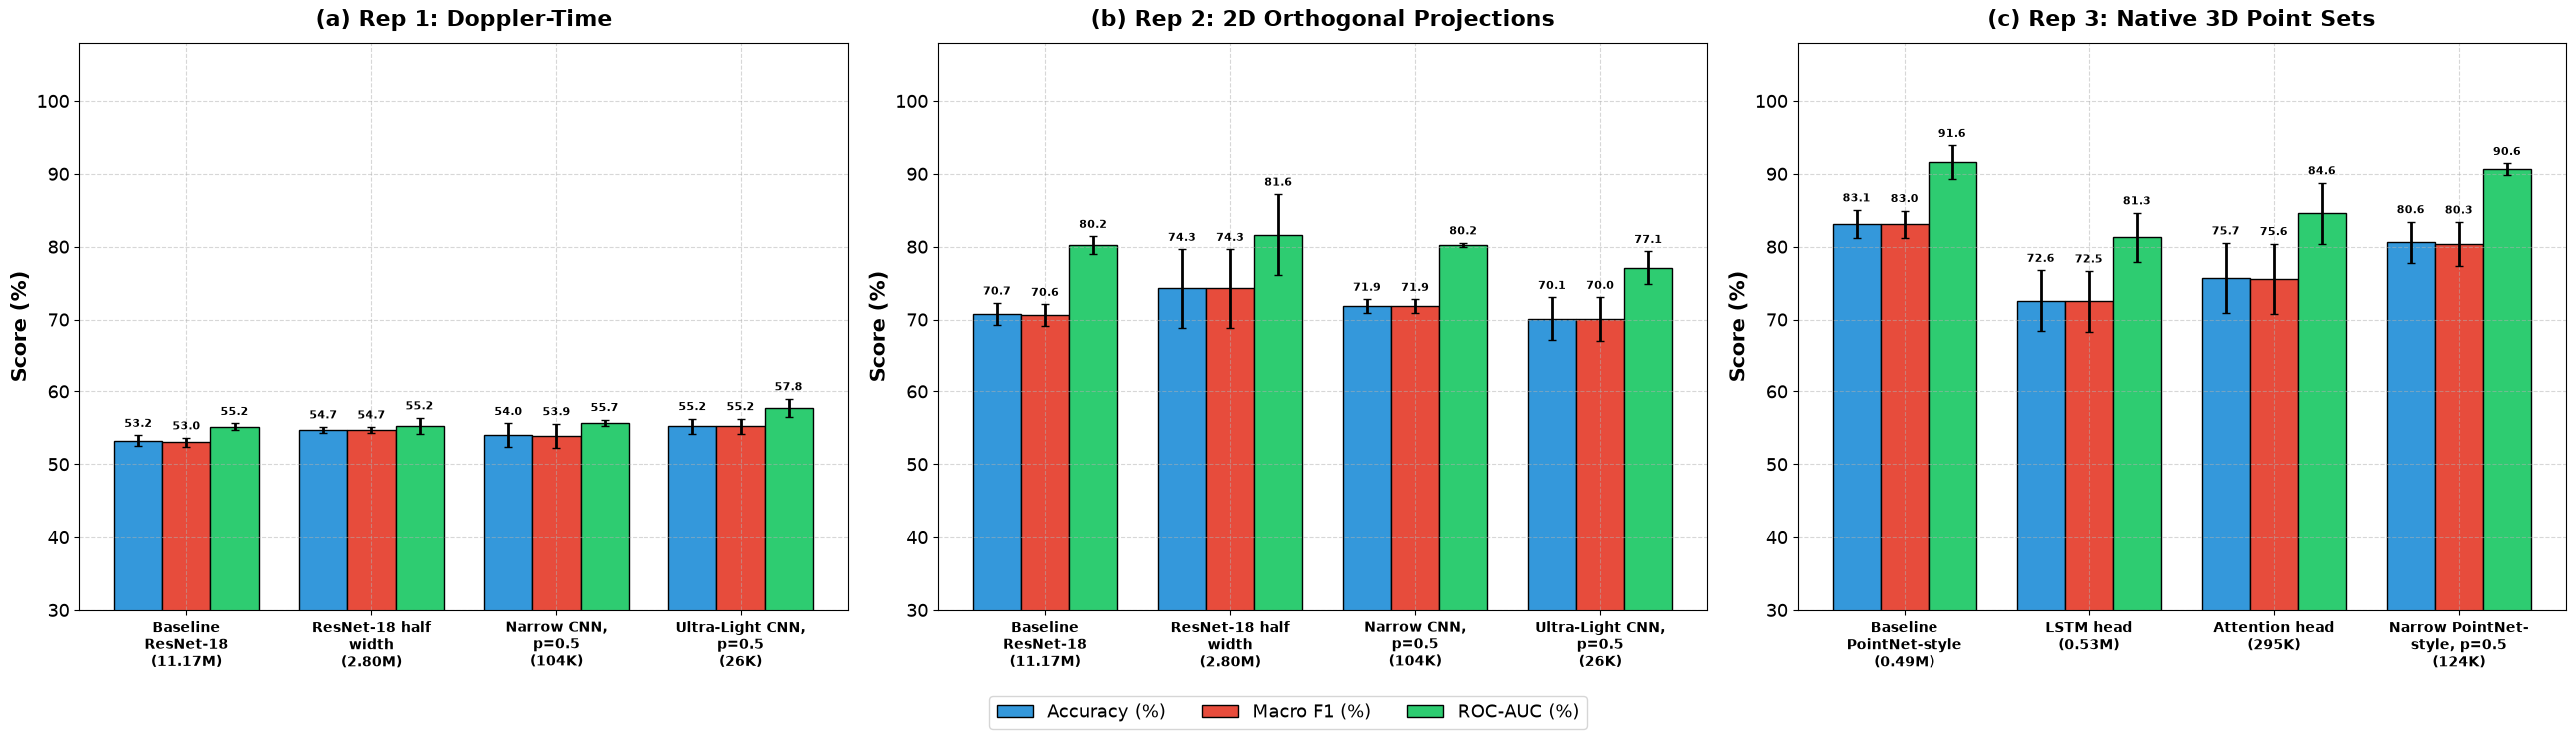

Saved Figure 4 to: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\figure4_model_size_ablation.png


In [14]:
# Cell 14: Figure 4 - Model-size & architecture ablation (labels and parameter counts come from the code)
fig, axes = plt.subplots(1, 3, figsize=(26, 7.5))
panel_titles = {"rep1": "(a) Rep 1: Doppler-Time", "rep2": "(b) Rep 2: 2D Orthogonal Projections", "rep3": "(c) Rep 3: Native 3D Point Sets"}

for ax_idx, rk in enumerate(REPRESENTATIONS):
    specs = MODEL_SPECS[rk]
    labels = [s["label"] for s in specs]
    x_pos = np.arange(len(labels)); w = 0.26
    acc_m = [agg_arch_summary[rk][l]["accuracy"]["mean"] * 100 for l in labels]; acc_s = [agg_arch_summary[rk][l]["accuracy"]["std"] * 100 for l in labels]
    f1_m = [agg_arch_summary[rk][l]["macro_f1"]["mean"] * 100 for l in labels];  f1_s = [agg_arch_summary[rk][l]["macro_f1"]["std"] * 100 for l in labels]
    auc_m = [agg_arch_summary[rk][l]["roc_auc"]["mean"] * 100 for l in labels];  auc_s = [agg_arch_summary[rk][l]["roc_auc"]["std"] * 100 for l in labels]

    b1 = axes[ax_idx].bar(x_pos - w, acc_m, yerr=acc_s, width=w, label="Accuracy (%)", color="#3498db", edgecolor="black", capsize=3)
    b2 = axes[ax_idx].bar(x_pos,     f1_m,  yerr=f1_s,  width=w, label="Macro F1 (%)", color="#e74c3c", edgecolor="black", capsize=3)
    b3 = axes[ax_idx].bar(x_pos + w, auc_m, yerr=auc_s, width=w, label="ROC-AUC (%)", color="#2ecc71", edgecolor="black", capsize=3)

    tick_labels = [f"{textwrap.fill(s['name'], 16)}\n({fmt_params(s['params'])})" for s in specs]
    axes[ax_idx].set_xticks(x_pos); axes[ax_idx].set_xticklabels(tick_labels, fontweight="bold", fontsize=10)
    axes[ax_idx].set_ylabel("Score (%)", fontweight="bold")
    axes[ax_idx].set_ylim(30, 108)
    axes[ax_idx].set_title(panel_titles[rk], fontweight="bold", pad=12)
    axes[ax_idx].grid(True, linestyle="--", alpha=0.5)
    for bars, stds in zip((b1, b2, b3), (acc_s, f1_s, auc_s)):
        for bar, std in zip(bars, stds):
            h = bar.get_height()
            axes[ax_idx].text(bar.get_x() + bar.get_width() / 2.0, h + std + 0.8, f"{h:.1f}", ha="center", va="bottom", fontsize=8, fontweight="bold")

handles, leg_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, leg_labels, loc="lower center", ncol=3, frameon=True)
plt.tight_layout(rect=(0, 0.06, 1, 1))
fig4_path = BENCHMARKS_DIR / "figure4_model_size_ablation.png"
plt.savefig(fig4_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved Figure 4 to: {fig4_path}")


In [15]:
# Cell 15: Unified JSON Export (benchmark + ablation + parameter counts)

benchmark_results["ablation"] = {
    "per_seed_by_representation": arch_results_by_rep,
    "aggregate_summary_by_representation": agg_arch_summary,
    "parameter_counts": {rk: {s["name"]: s["params"] for s in MODEL_SPECS[rk]} for rk in REPRESENTATIONS},
    "note": "Variants are evaluated directly on the held-out folds without tuning."
}
with open(json_out_path, "w", encoding="utf-8") as f:
    json.dump(benchmark_results, f, indent=2)
print(f"Successfully updated JSON export at: {json_out_path}")


Successfully updated JSON export at: c:\Users\joeyw\GitProjects\klas-1-team-2\mmWaves\ti_radar_pipeline\models\benchmarks\results_benchmark.json


 ---

 ## 5. How to read the results



 1. **Primary comparison (Cell 7/8):** three representations, each with its standard backbone (ResNet-18 for the grids, PointNet-style network for the point set), same windows, folds, seeds and training recipe.

 2. **Model-size ablation (Cells 12-14):** shows whether a difference between the representations can be explained by model size. The half-width ResNet-18 (about 2.8M) sits between the 11.17M baseline and the shortcut-free 104K/26K CNNs.

 3. **Rep 3 ablation:** the LSTM and attention heads test whether temporal modelling over the 10 frames helps; the narrow network tests model size.

 4. **Limits:** three subjects, overlapping windows (50%), seeds that only change weight initialization and batch order, and ablation variants that are evaluated on the held-out folds without tuning. The standard deviations over three seeds understate the true uncertainty.